In [ ]:
#AAAAAAAAAAAAAAAAAAAAAAAAAAA

#    /\_/\          MIAOOOOOO
#   ( o.o )   <-- Il gatto della qualità del codice veglia su di te.
#    > ^ <

In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import matthews_corrcoef,f1_score, confusion_matrix, precision_score, recall_score, balanced_accuracy_score
import matplotlib.pyplot as plt
import argparse
from pathlib import Path

In [3]:
def performance_metrics(y_test,y_pred):
    '''This function is used to store the performance metrics of the model on the benchmark set'''
    mcc= matthews_corrcoef(y_test, y_pred)
    precision= precision_score(y_test, y_pred)
    recall= recall_score(y_test, y_pred)
    f1=f1_score(y_test, y_pred)
    cm=confusion_matrix(y_test, y_pred)
    bal_acc=balanced_accuracy_score(y_test, y_pred)

    return mcc, f1, cm, precision, recall, bal_acc

In [3]:
df=pd.read_csv('/home/um40/LB2_project_Group_1/Models/SVM/SVM_pred_vs_test.csv')

In [15]:
df

,Uniprot_ID,true_class,pred_class
0,A0A0B5L781,0,0
1,A0A0D1CRC9,0,0
2,A0A0D1DWQ2,1,1
3,A0A0D1E3S6,0,0
4,A0A0F7YZQ7,1,1
...,...,...,...
1941,S0DHV6,0,0
1942,S8EZA7,0,0
1943,S8F527,0,0
1944,W2SDE2,0,0


In [16]:
performance=performance_metrics(df['true_class'], df['pred_class'])
performance

(0.8943876693297782,
 0.9061784897025171,
 array([[1707,   18],
        [  23,  198]]),
 0.9166666666666666,
 0.8959276018099548,
 0.9427464096006295)

In [5]:
data=pd.read_csv('/home/um40/LB2_project_Group_1/Data_preparation/Cleaned_merged_dataset.tsv',sep='\t')
data

,class,ID,organism_name,kingdom,length,cleavage_pos,early_trans,fold
0,0,Q6YN16,Homo sapiens,Metazoa,418,0,False,4
1,0,Q9Y3I1,Homo sapiens,Metazoa,522,0,False,3
2,0,P30044,Homo sapiens,Metazoa,214,0,False,5
3,0,P07954,Homo sapiens,Metazoa,510,0,False,-1
4,0,P21549,Homo sapiens,Metazoa,392,0,False,-1
...,...,...,...,...,...,...,...,...
9723,1,Q7M3V1,Chelonus sp. nr. curvimaculatus,Metazoa,246,20,False,5
9724,1,Q8MMH5,Pimpla hypochondriaca,Metazoa,61,20,False,3
9725,1,I6RA76,Scolopendra mutilans,Metazoa,64,18,False,1
9726,1,P0DPU7,Scolopendra dehaani,Metazoa,78,25,False,-1


In [ ]:
tn_tm=data.loc[data['ID'].isin(TN) & data['early_trans']==True]['ID'].tolist()
print(len(tn_tm))
fp_trans=data.loc[data['ID'].isin(FP) & data['early_trans']==True]['ID'].tolist()

print(len(fp_trans))

tp_trans=data.loc[data['ID'].isin(TP) & data['early_trans']==True]['ID'].tolist()
print(len(tp_trans))
fn_trans=data.loc[data['ID'].isin(FN) & data['early_trans']==True]['ID'].tolist()
print(len(fn_trans))

## sono meno perche sono solo sul test set, mentre i primi sono sul dataset completo


87
19
0
0


In [40]:
data['early_trans'].value_counts()

False    9186
True      542
Name: early_trans, dtype: int64

In [11]:

def performance_metrics(y_test,y_pred):
    '''This function is used to store the performance metrics of the model on the benchmark set'''
    mcc= matthews_corrcoef(y_test, y_pred)
    precision= precision_score(y_test, y_pred)
    recall= recall_score(y_test, y_pred)
    f1=f1_score(y_test, y_pred)
    cm=confusion_matrix(y_test, y_pred)
    bal_acc=balanced_accuracy_score(y_test, y_pred)

    return mcc, f1, cm, precision, recall, bal_acc


def labeling_function(df):
    TN=df.loc[(df['true_class']==0) & (df['pred_class']==0)]['UniprotID'].tolist()

    TP=df.loc[(df['true_class']==1) & (df['pred_class']==1)]['UniprotID'].tolist()

    FN=df.loc[(df['true_class']==1) & (df['pred_class']==0)]['UniprotID'].tolist()

    FP=df.loc[(df['true_class']==0) & (df['pred_class']==1)]['UniprotID'].tolist()

    return TN, TP, FN, FP


def plot_taxa_distribution(FP,FN,data):
    FP_taxa=data.loc[data['ID'].isin(FP)]['kingdom'].value_counts()
    FN_taxa=data.loc[data['ID'].isin(FN)]['kingdom'].value_counts()

    taxa_df = pd.DataFrame({'False Positives': FP_taxa, 'False Negatives': FN_taxa})
    #taxa_df_normalized = taxa_df.div(taxa_df.sum(axis=1), axis=0) * 100 

    taxa_df.plot(kind='bar', color=['red', 'blue'], alpha=0.5)


    plt.title('Distribution of False Positives and False Negatives across Taxa', weight='bold')
    plt.xlabel('Taxa')
    plt.ylabel('percentage')
    plt.legend()
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig('taxa_distribution.png', dpi=300)
    plt.show()



def Helix_presence(FP,data):
    FP_helix = data.loc[data['ID'].isin(FP) & (data['early_trans'] == True)]['early_trans'].value_counts()
    FP_No_helix = data.loc[data['ID'].isin(FP) & (data['early_trans'] == False)]['early_trans'].value_counts()

    counts = pd.DataFrame({'Helix Presence': FP_helix, 'No Helix Presence': FP_No_helix})

    counts.plot(kind='bar', color=['red', 'orange'], alpha=0.5)

    plt.title('Distribution of False Positives across Helix Presence', weight='bold')
    plt.xlabel('Helix Presence')
    plt.ylabel('Count')
    plt.legend()
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig('helix_distribution.png', dpi=300)
    plt.show()


In [8]:
TN, TP, FN, FP = labeling_function(df)

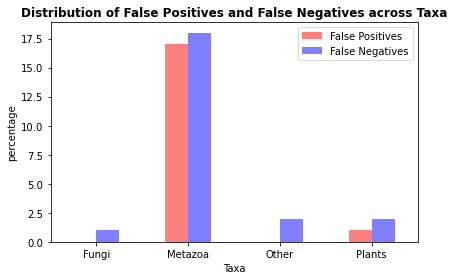

In [12]:
plot_taxa_distribution(FP,FN,data)

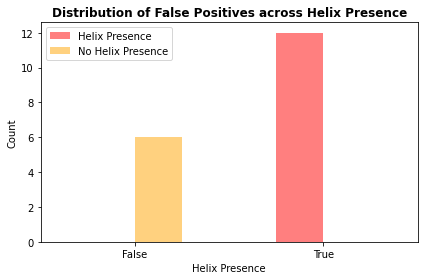

In [10]:
Helix_presence(FP,data)